# All — every PlaneFR figure and Excel workbook in a single run

One cell per figure function of `planefr_lib`. Each figure is saved in
`figures/<function>/[<scenario group>/]` with the Excel workbook of its data
(same name, `.xlsx`).

**Every choice is a CAPITALIZED parameter**, with the possible values in comment:
- parameters shared by several functions: cell *0. Shared parameters*;
- parameters specific to one function: at the top of its cell.

Processed scenarios are cached by scenario group (`scenarios(group)`): several
figures on the same group reuse them.

## 0. Shared parameters

In [7]:
# ---- Scenario groups (folders of data/Outputs_MatMat/<version>/, see the list printed below) ----
GROUP_France = "CONF"               # France scenarios, all figures except 5 (e.g. "CONF", "ADEME", "no_SSP", "SSP2_2050"...), without "_agri"
GROUP_REGIONS = "REGIONS"            # geographies of the multi-regions synthesis (5): a 2019 display group of scenario_groups.json
AGRI = True                      # True: agri-food variant of both groups ("<group>_agri": pressures of the agri-food system only)

# ---- Boundaries ----
SHARING_PRINCIPLE = "EPC"         # national budget = world budget x share in budget_shares.xlsx:
                                  #   "EPC" (equal per capita) or "CTR" (capability to reduce)
DISPLAY_BOUNDS = True             # True: Lower/High-Risk Boundary shown in addition to the Safe Boundary; False: Safe Boundary only
SCALE_UB = False                   # True: scale rescaled per LP so that the High-Risk Boundary is aligned (2L); False: common nL scale
SHOW_DLS = True                   # True: Decent Living Standards (social floor) shown (CBA figures only)

# ---- Display ----
SHOW_PBA = True                   # True: production-based accounting (PBA) shown next to the CBA
SHOW_VALUES = False                # True: values / overshoot levels annotated on the bars
GROUP_BY_CATEGORY = True          # stacking order: True = cat1-dom, cat1-imp, cat2-dom...; False = all dom then all imp
DPI = 300                         # resolution of the saved .png

# =====================================================================
%load_ext autoreload
%autoreload 2

import sys
from functools import lru_cache
from pathlib import Path

notebooks_dir = Path.cwd()
while not (notebooks_dir / "planefr_lib").exists() and notebooks_dir != notebooks_dir.parent:
    notebooks_dir = notebooks_dir.parent
if str(notebooks_dir) not in sys.path:
    sys.path.insert(0, str(notebooks_dir))

import matplotlib.pyplot as plt

from planefr_lib import config, figure_export, io, processing
from planefr_lib.plot_bubble import (export_indicator_tables_excel, load_indicator_tables_excel,
                                     create_driver_comparison)
from planefr_lib.plot_overshoot import create_multi_regions_synthesis
from planefr_lib.plot_process_breakdown import create_biodiversity_process_contribution
from planefr_lib.plot_radial_synthesis import create_radial_synthesis
from planefr_lib.plot_stacked_bar import (create_footprint_decomposition_by_scenario,
                                          create_footprint_decomposition)

# Agri-food variant: "<group>_agri" groups, built automatically by build_scenario_groups.py
if AGRI:
    GROUP_France = GROUP_France.removesuffix(io.AGRI_GROUP_SUFFIX) + io.AGRI_GROUP_SUFFIX
    GROUP_REGIONS = GROUP_REGIONS.removesuffix(io.AGRI_GROUP_SUFFIX) + io.AGRI_GROUP_SUFFIX

print("Available scenario groups:", config.get_scenario_groups())
# Sub-folder of the figures not saved per group (cells 3 to 6), so that AGRI = True does not overwrite them
AGRI_DIR = (io.AGRI_GROUP_SUFFIX,) if AGRI else ()

print(f"Displayed groups: {GROUP_France}, {GROUP_REGIONS}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Available scenario groups: ['2019_raw', 'ADEME', 'ADEME_agri', 'BdF', 'BdF_agri', 'CONF', 'CONF_agri', 'REGIONS', 'REGIONS_agri', 'S1+', 'SSP2_19_2050', 'SSP2_19_2050_agri', 'SSP2_19_Sus_2050', 'SSP2_19_Sus_2050_agri', 'SSP2_2050', 'SSP2_2050_agri', 'no_SSP', 'no_SSP_agri']
Displayed groups: CONF_agri, REGIONS_agri


## Shared data and helpers

In [8]:
bridge_matrices_df = io.load_bridge_matrices()
dls_df = io.load_dls()
pop_df = io.load_population_df()
shares_df = io.load_budget_shares_df()


@lru_cache(maxsize=None)
def inputs(group):
    """(cf_df, boundaries_df) of a scenario group."""
    return io.load_characterization_factors(group), io.load_boundaries(group)


@lru_cache(maxsize=None)
def scenarios(group):
    """Processed scenarios of a group (cached): folders, names, data, indicator_to_lp."""
    cf_df, boundaries_df = inputs(group)
    folders = config.get_scenario_folders(exclude_2019=True, scenario_group=group)
    data, to_lp = [], []
    for f in folders:
        d, lp = processing.process_scenario(f, cf_df, bridge_matrices_df, boundaries_df)
        data.append(d); to_lp.append(lp)
    print(f"[{group}] {len(folders)} scenarios: {[f.name for f in folders]}")
    return folders, [f.name for f in folders], data, to_lp


def save(fig, path):
    """Save the figure (its Excel workbook is written by the plot function)."""
    fig.savefig(path, dpi=DPI, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved: {path}")

## 1. Base year region comparison

c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\config.py:232: UserWarning: Group 'REGIONS_agri' does not contain Base_year_2015: the reference scenario (REFERENCE_SCENARIO_IDX) will be the first one in alphabetical order.
  warnings.warn(
c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\plot_overshoot.py:368: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  show_pba=True). A min share giving a smaller budget, hence a larger


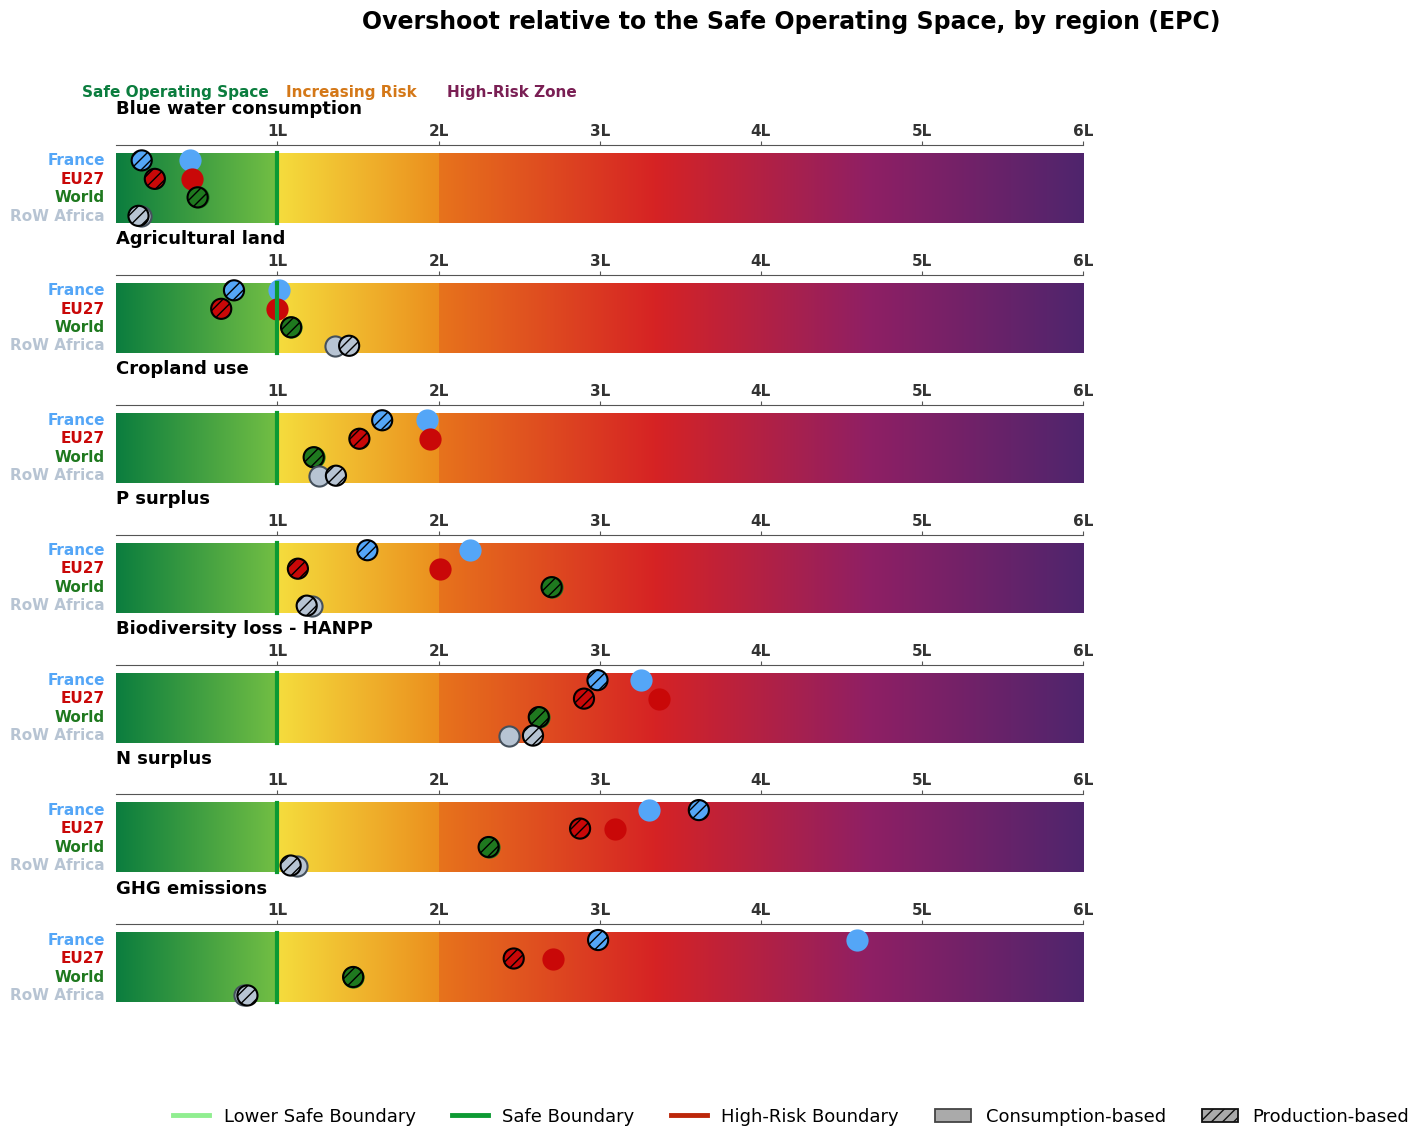

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\multi-regions_synthesis\REGIONS_agri\overshoot_safe_operating_space_by_region.png


In [9]:
SENSITIVITY = False              # True: min/max segment of the sharing principle on each bubble
X_MAIN_MAX = 6                    # right bound of the main axis, in multiples of the Safe Boundary
SHOW_VALUE_OVERSHOOT = True       # True: one "nL" axis per bar; False: a single axis at the top
REGIONS_TITLE = f"Overshoot relative to the Safe Operating Space, by region ({SHARING_PRINCIPLE})"

cf_df, boundaries_df = inputs(GROUP_REGIONS)
folders = config.get_scenario_folders(exclude_2019=True, scenario_group=GROUP_REGIONS)
data_absolute = [processing.process_scenario_absolute(f, cf_df, boundaries_df) for f in folders]

path = config.figure_dir("multi-regions_synthesis", GROUP_REGIONS) / "overshoot_safe_operating_space_by_region.png"
fig = create_multi_regions_synthesis(
    all_scenarios_data=data_absolute, boundaries_df=boundaries_df, shares_df=shares_df,
    scenario_names=[f.name for f in folders], x_main_max=X_MAIN_MAX,
    display_bounds=DISPLAY_BOUNDS, show_pba=SHOW_PBA,
    show_value_overshoot=SHOW_VALUE_OVERSHOOT, title=REGIONS_TITLE,
    sharing_principle=SHARING_PRINCIPLE, sensitivity=SENSITIVITY, scale_UB=SCALE_UB,
    pop_df=pop_df,  # sensitivity of W: per-capita limit depending on the population period
    excel_path=path.with_suffix(".xlsx"))
save(fig, path)

## 2. Radial scenario comparison

c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\config.py:232: UserWarning: Group 'CONF_agri' does not contain Base_year_2015: the reference scenario (REFERENCE_SCENARIO_IDX) will be the first one in alphabetical order.
  warnings.warn(


[CONF_agri] 5 scenarios: ['2015', 'S1', 'S1+', 'S4', 'TREND']


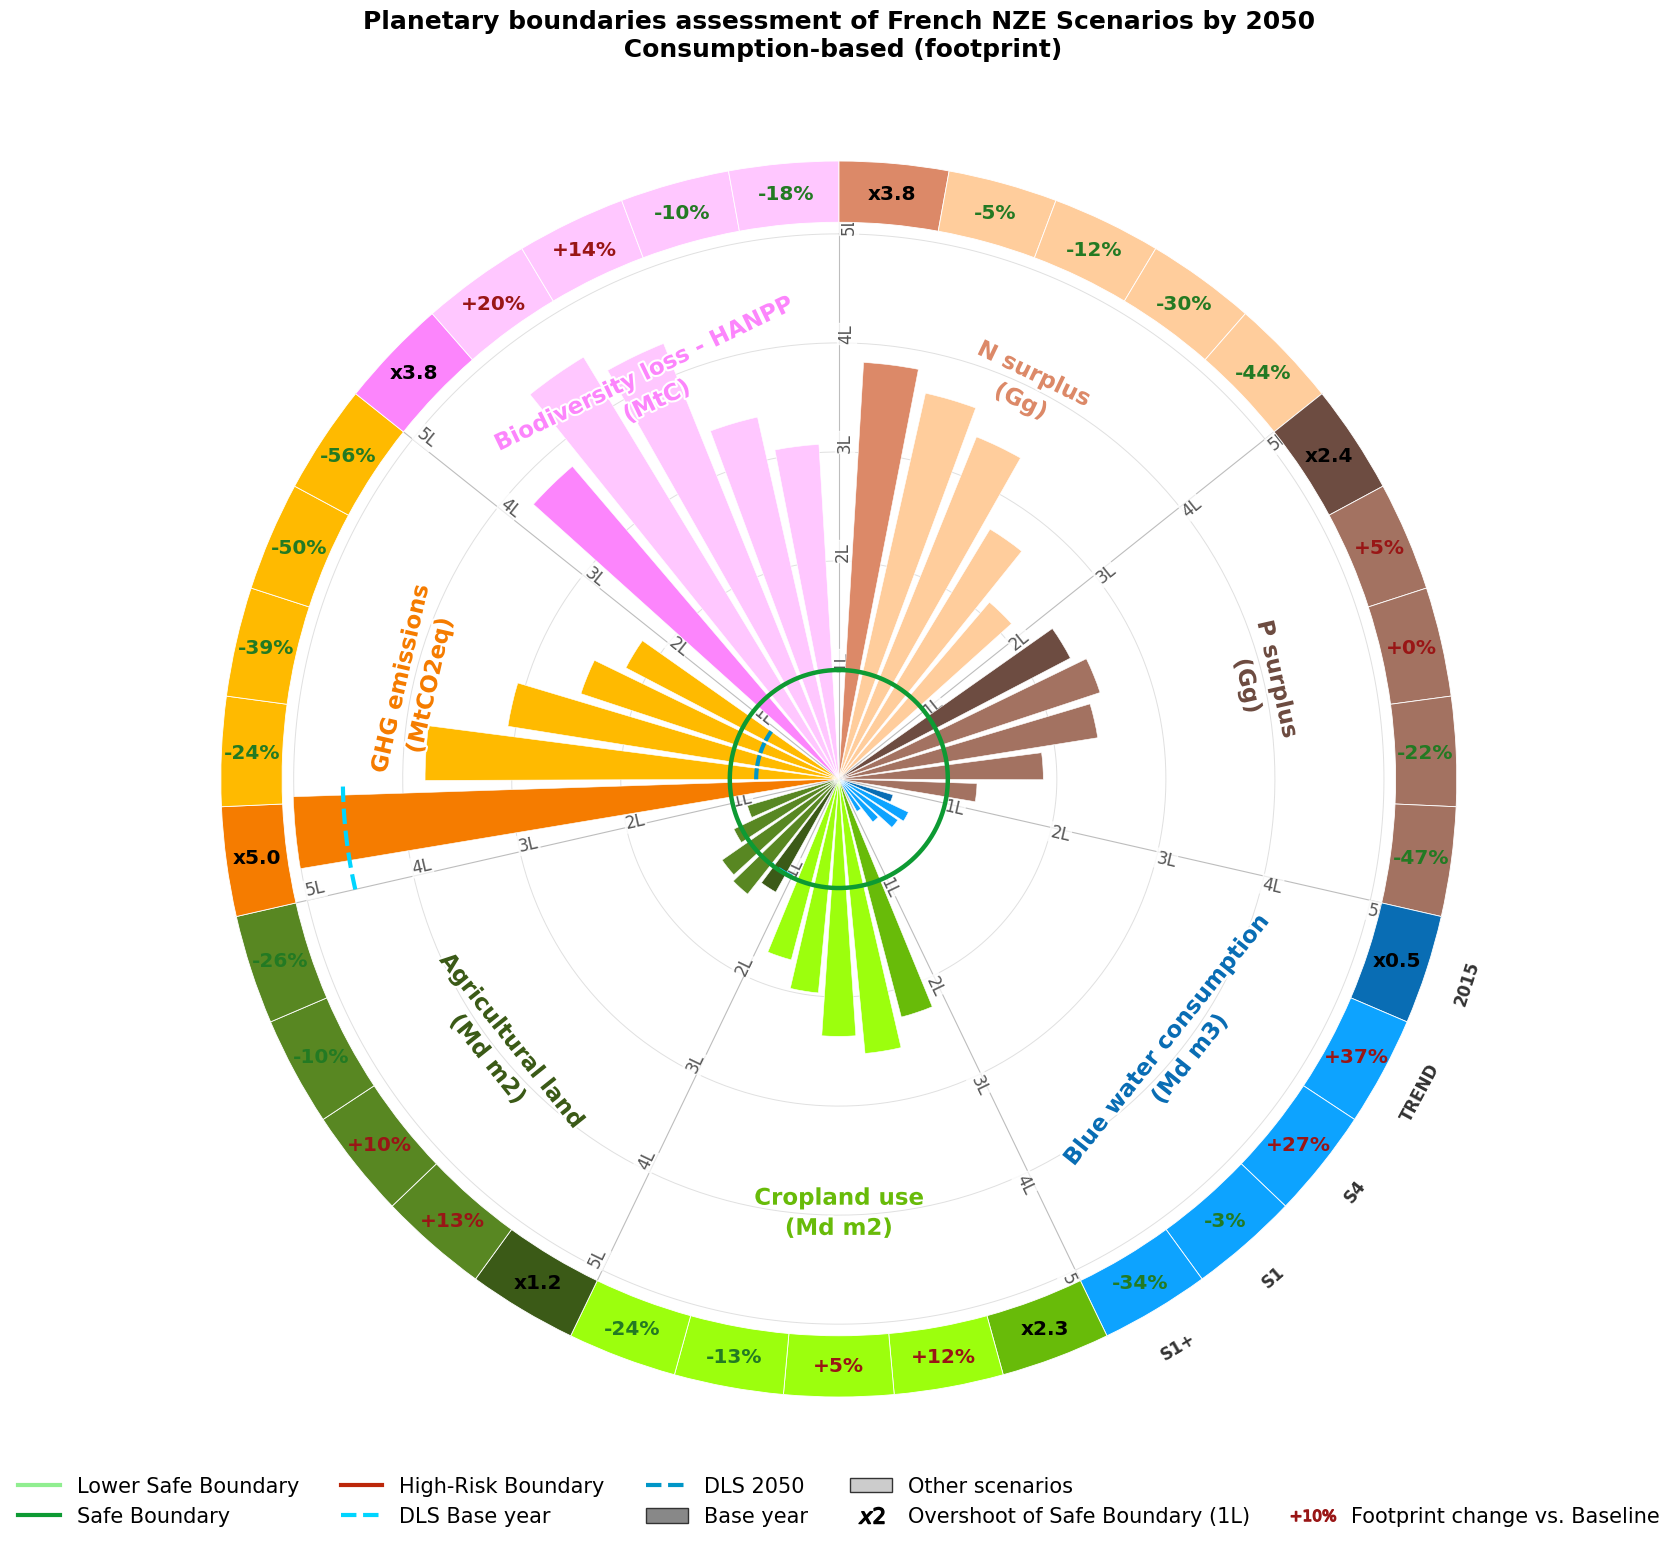

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\radial_synthesis\CONF_agri\radial_synthesis_cba_all_scenarios.png


In [10]:
RADIAL_ACCOUNTINGS = ["cba"]  # figures to make: "cba", "pba", "cba+pba" (both side by side)
RADIAL_POWER = 1             # radius = (value / Safe Boundary) ** power: 1 = linear, 0.5 = sqrt, smaller = more dilated
SCALE_DIFF = False            # True: radial axis capped at 6L, larger bars truncated (incompatible with SCALE_UB)
BDF_SHEETS = []                   # works with GROUP_France = BdF; sheets of the BdF file (e.g. ["décile"])
RADIAL_TITLES = {                 # figure titles (None = automatic)
    "cba": "Planetary boundaries assessment of French NZE Scenarios by 2050\n Consumption-based (footprint)",
    "pba": "Planetary boundaries assessment of French NZE Scenarios by 2050\n Production-based (territorial)",
    "cba+pba": None,
}

folders, names, data, _ = scenarios(GROUP_France)
cf_df, boundaries_df = inputs(GROUP_France)
out_dir = config.figure_dir("radial_synthesis", GROUP_France)

common = dict(dls_df=dls_df, radial_power=RADIAL_POWER, display_bounds=DISPLAY_BOUNDS,
              scale_UB=SCALE_UB, scale_diff=SCALE_DIFF,
              sharing_principle=SHARING_PRINCIPLE, scenario_group=GROUP_France)
runs = [(acc, None) for acc in RADIAL_ACCOUNTINGS] + [("cba", sheet) for sheet in BDF_SHEETS]
for acc, bdf in runs:
    show_cba, show_pba = "cba" in acc, "pba" in acc
    name = f"radial_synthesis_bdf_{bdf}" if bdf else f"radial_synthesis_{acc.replace('+', '_')}_all_scenarios"
    path = out_dir / f"{name}.png"
    fig, _ = create_radial_synthesis(
        data, boundaries_df, names, show_cba=show_cba, show_pba=show_pba,
        show_dls=SHOW_DLS and show_cba,  # the DLS is a consumption floor: not shown on PBA-only wheels
        title=None if bdf else RADIAL_TITLES.get(acc), Bdf=bdf, **common,
        excel_path=path.with_suffix(".xlsx"))
    save(fig, path)

## 3. Footprint decomposition per scenario

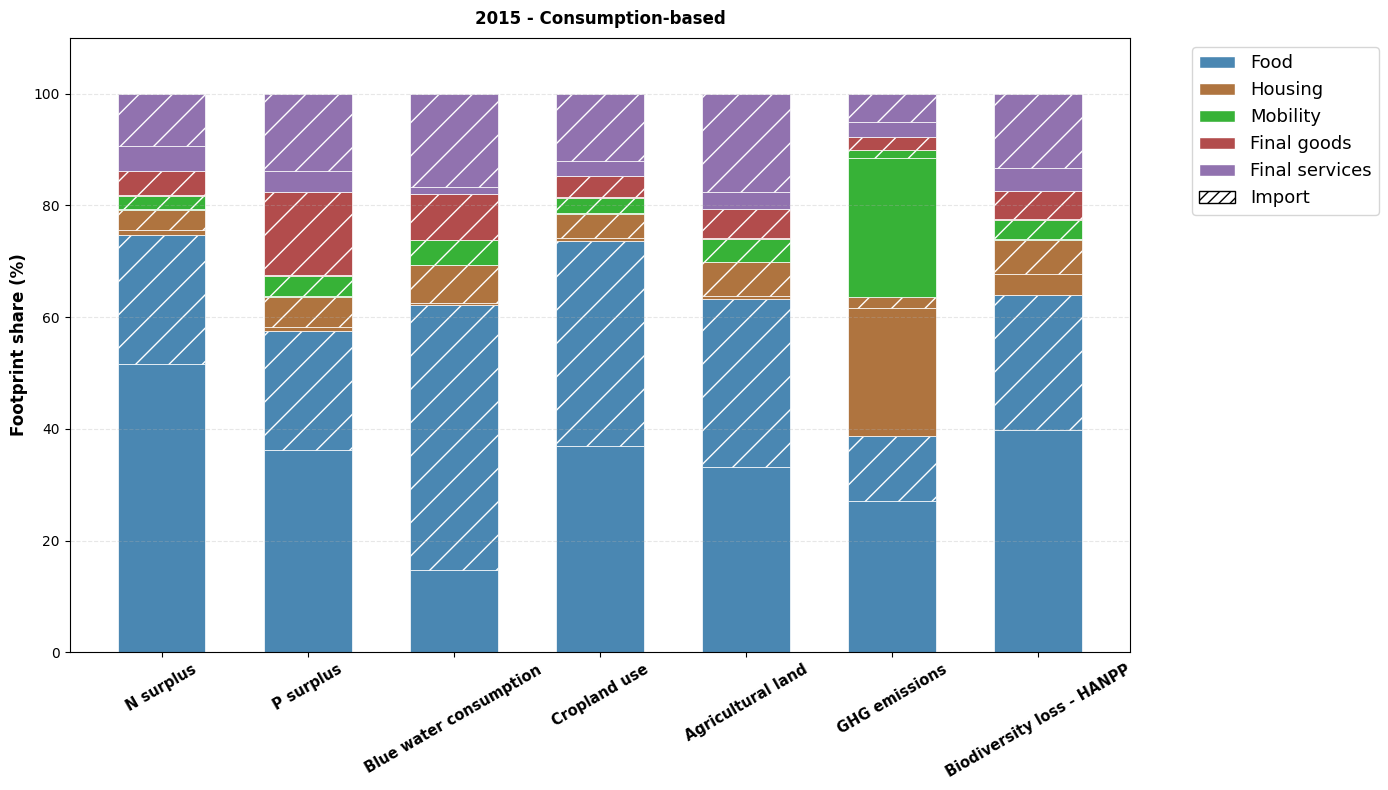

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\footprint_decomposition\_agri\scenario_00_2015.png


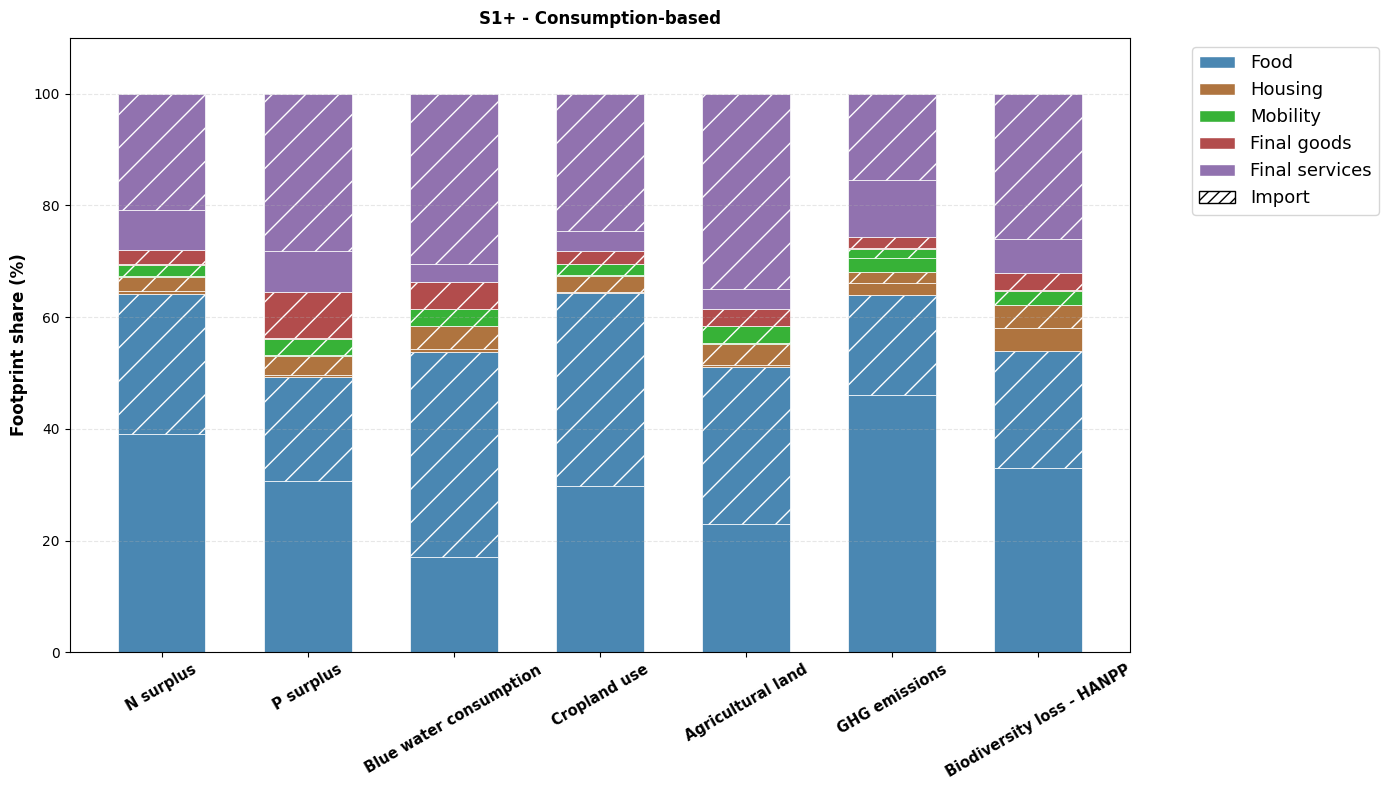

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\footprint_decomposition\_agri\scenario_02_S1+.png


In [11]:
DECOMPOSED_SCENARIOS = ["2015", "S1+"]  # GROUP_France scenarios (folder names) to decompose, one figure each

folders, names, data, to_lp = scenarios(GROUP_France)
cf_df, boundaries_df = inputs(GROUP_France)
out_dir = config.figure_dir("footprint_decomposition", *AGRI_DIR)

unknown = [s for s in DECOMPOSED_SCENARIOS if s not in names]
if unknown:
    raise ValueError(f"Scenarios not in group {GROUP_France!r}: {unknown} (available: {names})")

for name in DECOMPOSED_SCENARIOS:
    i = names.index(name)
    path = out_dir / f"scenario_{i:02d}_{name}.png"
    fig, _ = create_footprint_decomposition_by_scenario(
        data[i], boundaries_df, to_lp[i], scenario_name=name, group_by_category=GROUP_BY_CATEGORY,
        sharing_principle=SHARING_PRINCIPLE, show_values=SHOW_VALUES,
        excel_path=path.with_suffix(".xlsx"))
    save(fig, path)

## 4. Footprint variations decomposition

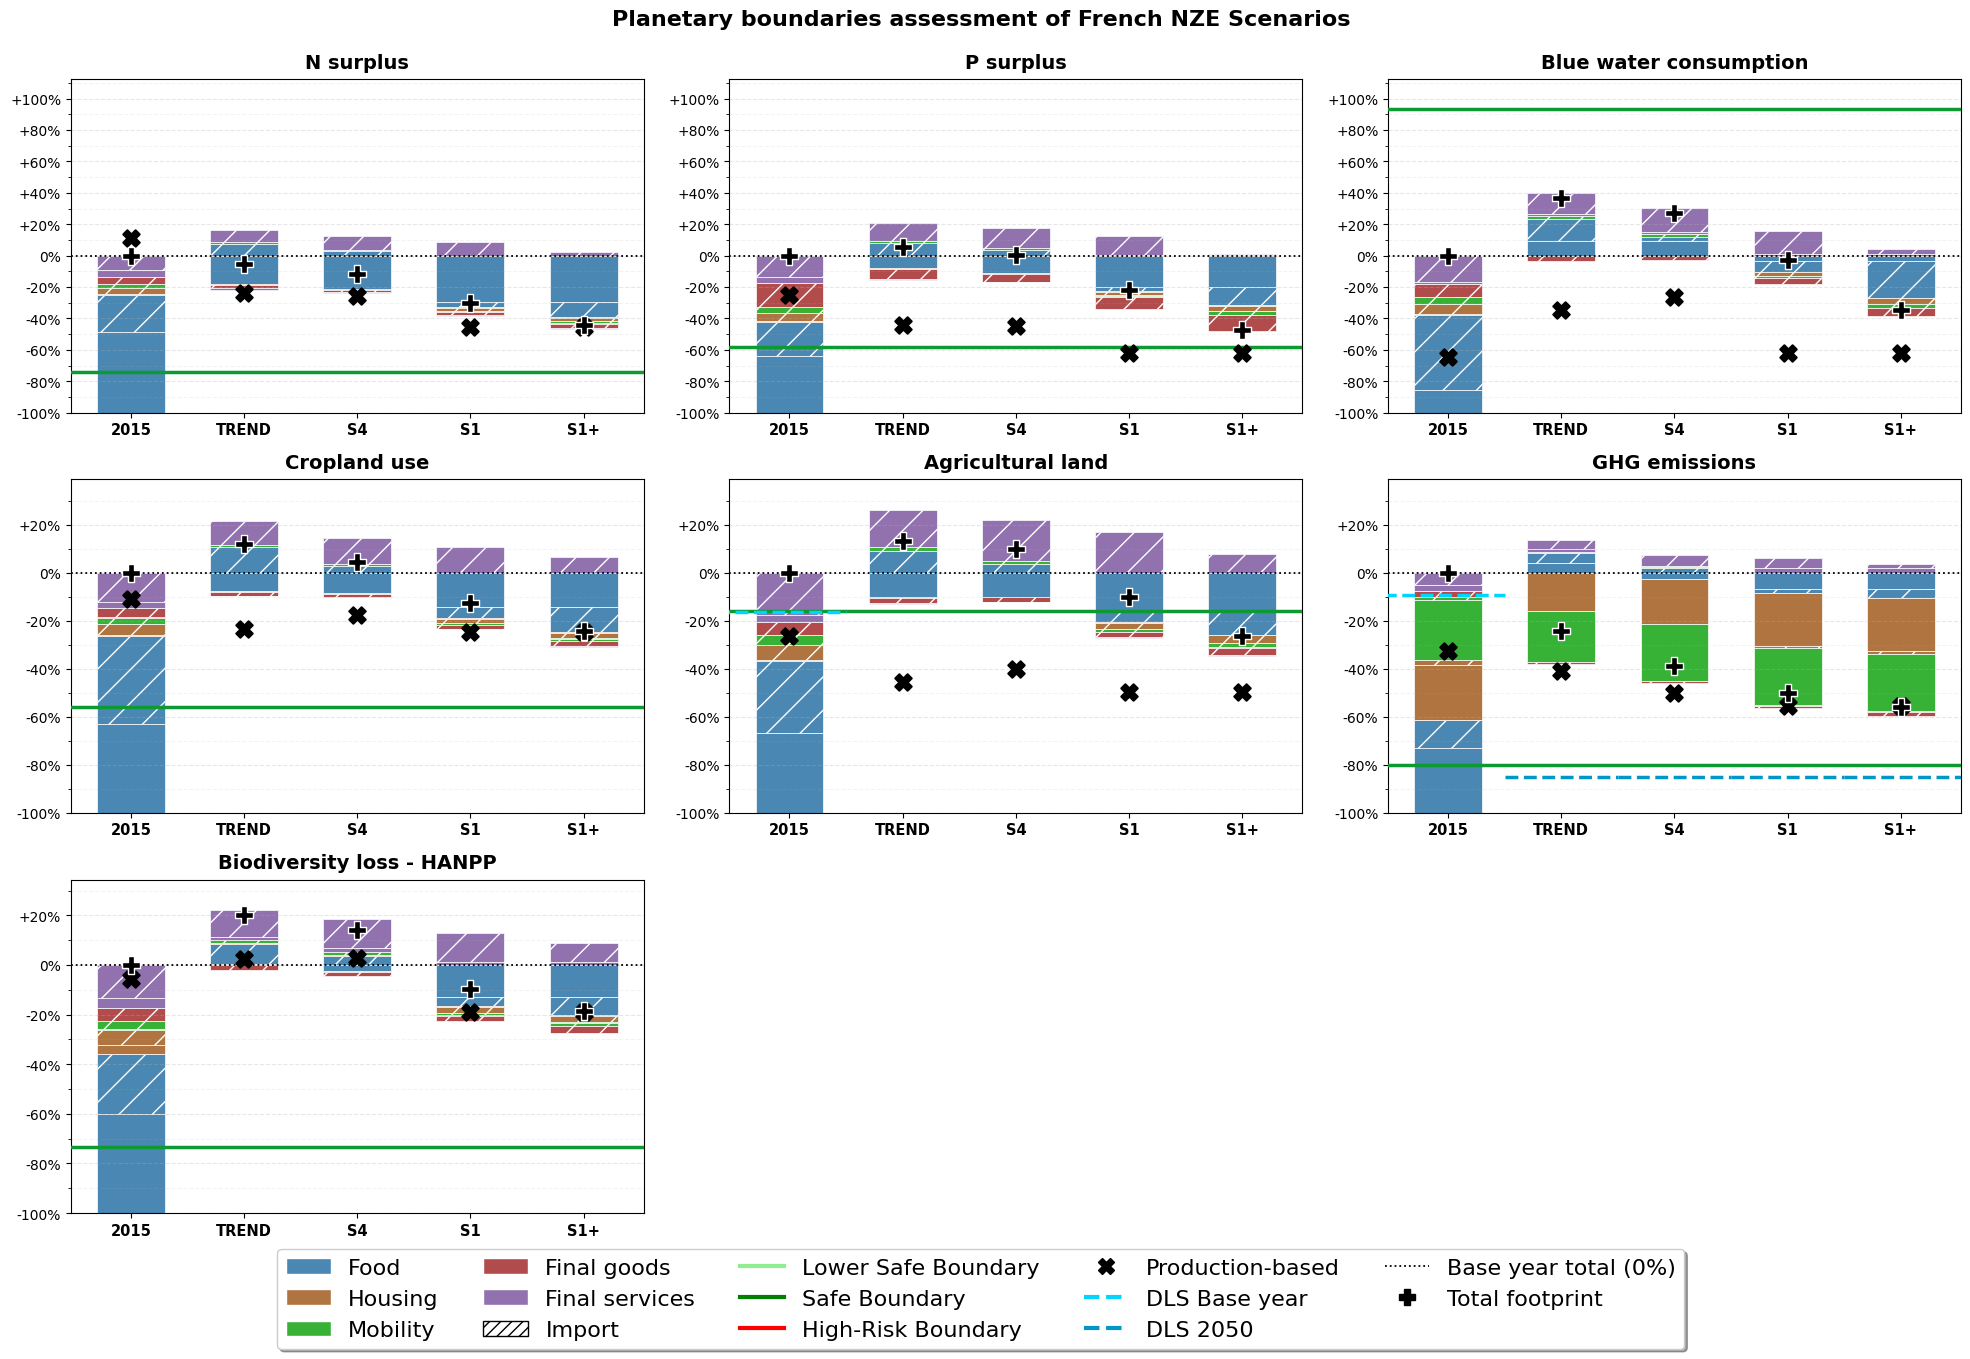

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\footprint_decomposition\_agri\synthesis_by_lp_all_scenarios.png


In [12]:
SHOW_VARIATION_BARS = True        # True: non-reference scenarios drawn as variations vs the reference; False: absolute bars

folders, names, data, to_lp = scenarios(GROUP_France)
cf_df, boundaries_df = inputs(GROUP_France)

path = config.figure_dir("footprint_decomposition", *AGRI_DIR) / "synthesis_by_lp_all_scenarios.png"
fig, _ = create_footprint_decomposition(
    data, boundaries_df, to_lp, names, dls_df,
    group_by_category=GROUP_BY_CATEGORY, show_pba=SHOW_PBA, show_dls=SHOW_DLS,
    show_values=SHOW_VALUES, display_bounds=DISPLAY_BOUNDS,
    show_variation_bars=SHOW_VARIATION_BARS, sharing_principle=SHARING_PRINCIPLE,
    scenario_group=GROUP_France, excel_path=path.with_suffix(".xlsx"))
save(fig, path)

## 5. Further decomposition of drivers

Excel table saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\driver_comparison\_agri\bubble_data_by_indicator_2015.xlsx
Excel table saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\driver_comparison\_agri\bubble_data_by_indicator_S1+.xlsx


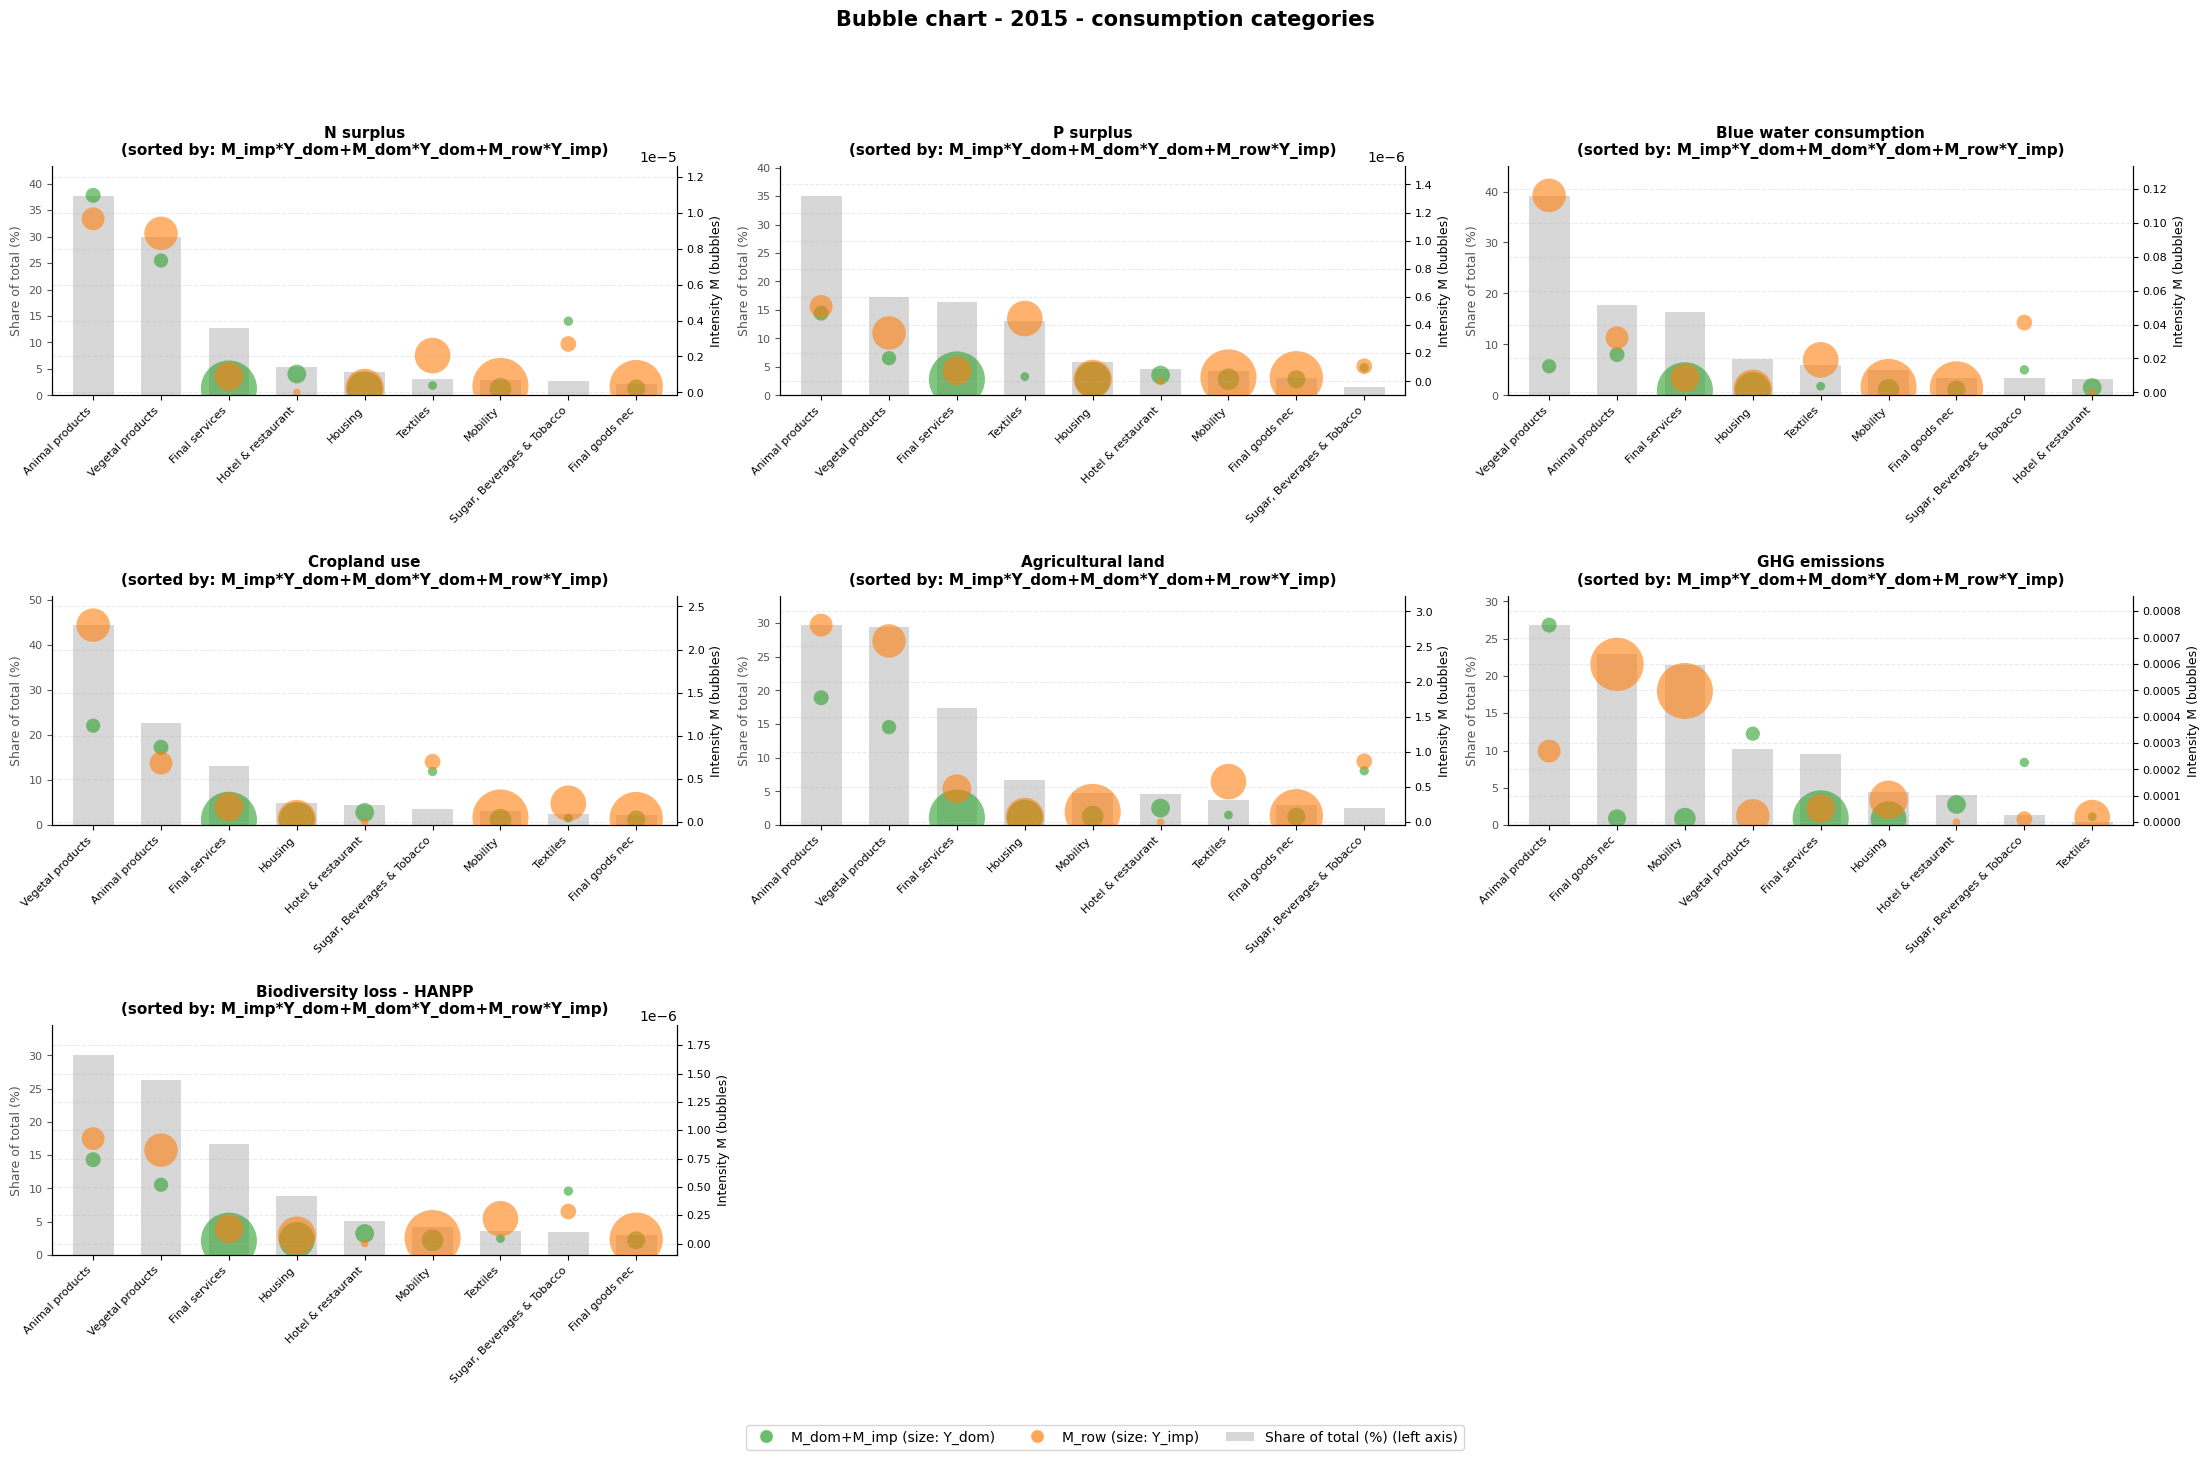

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\driver_comparison\_agri\bubble_chart_2015_categories.png


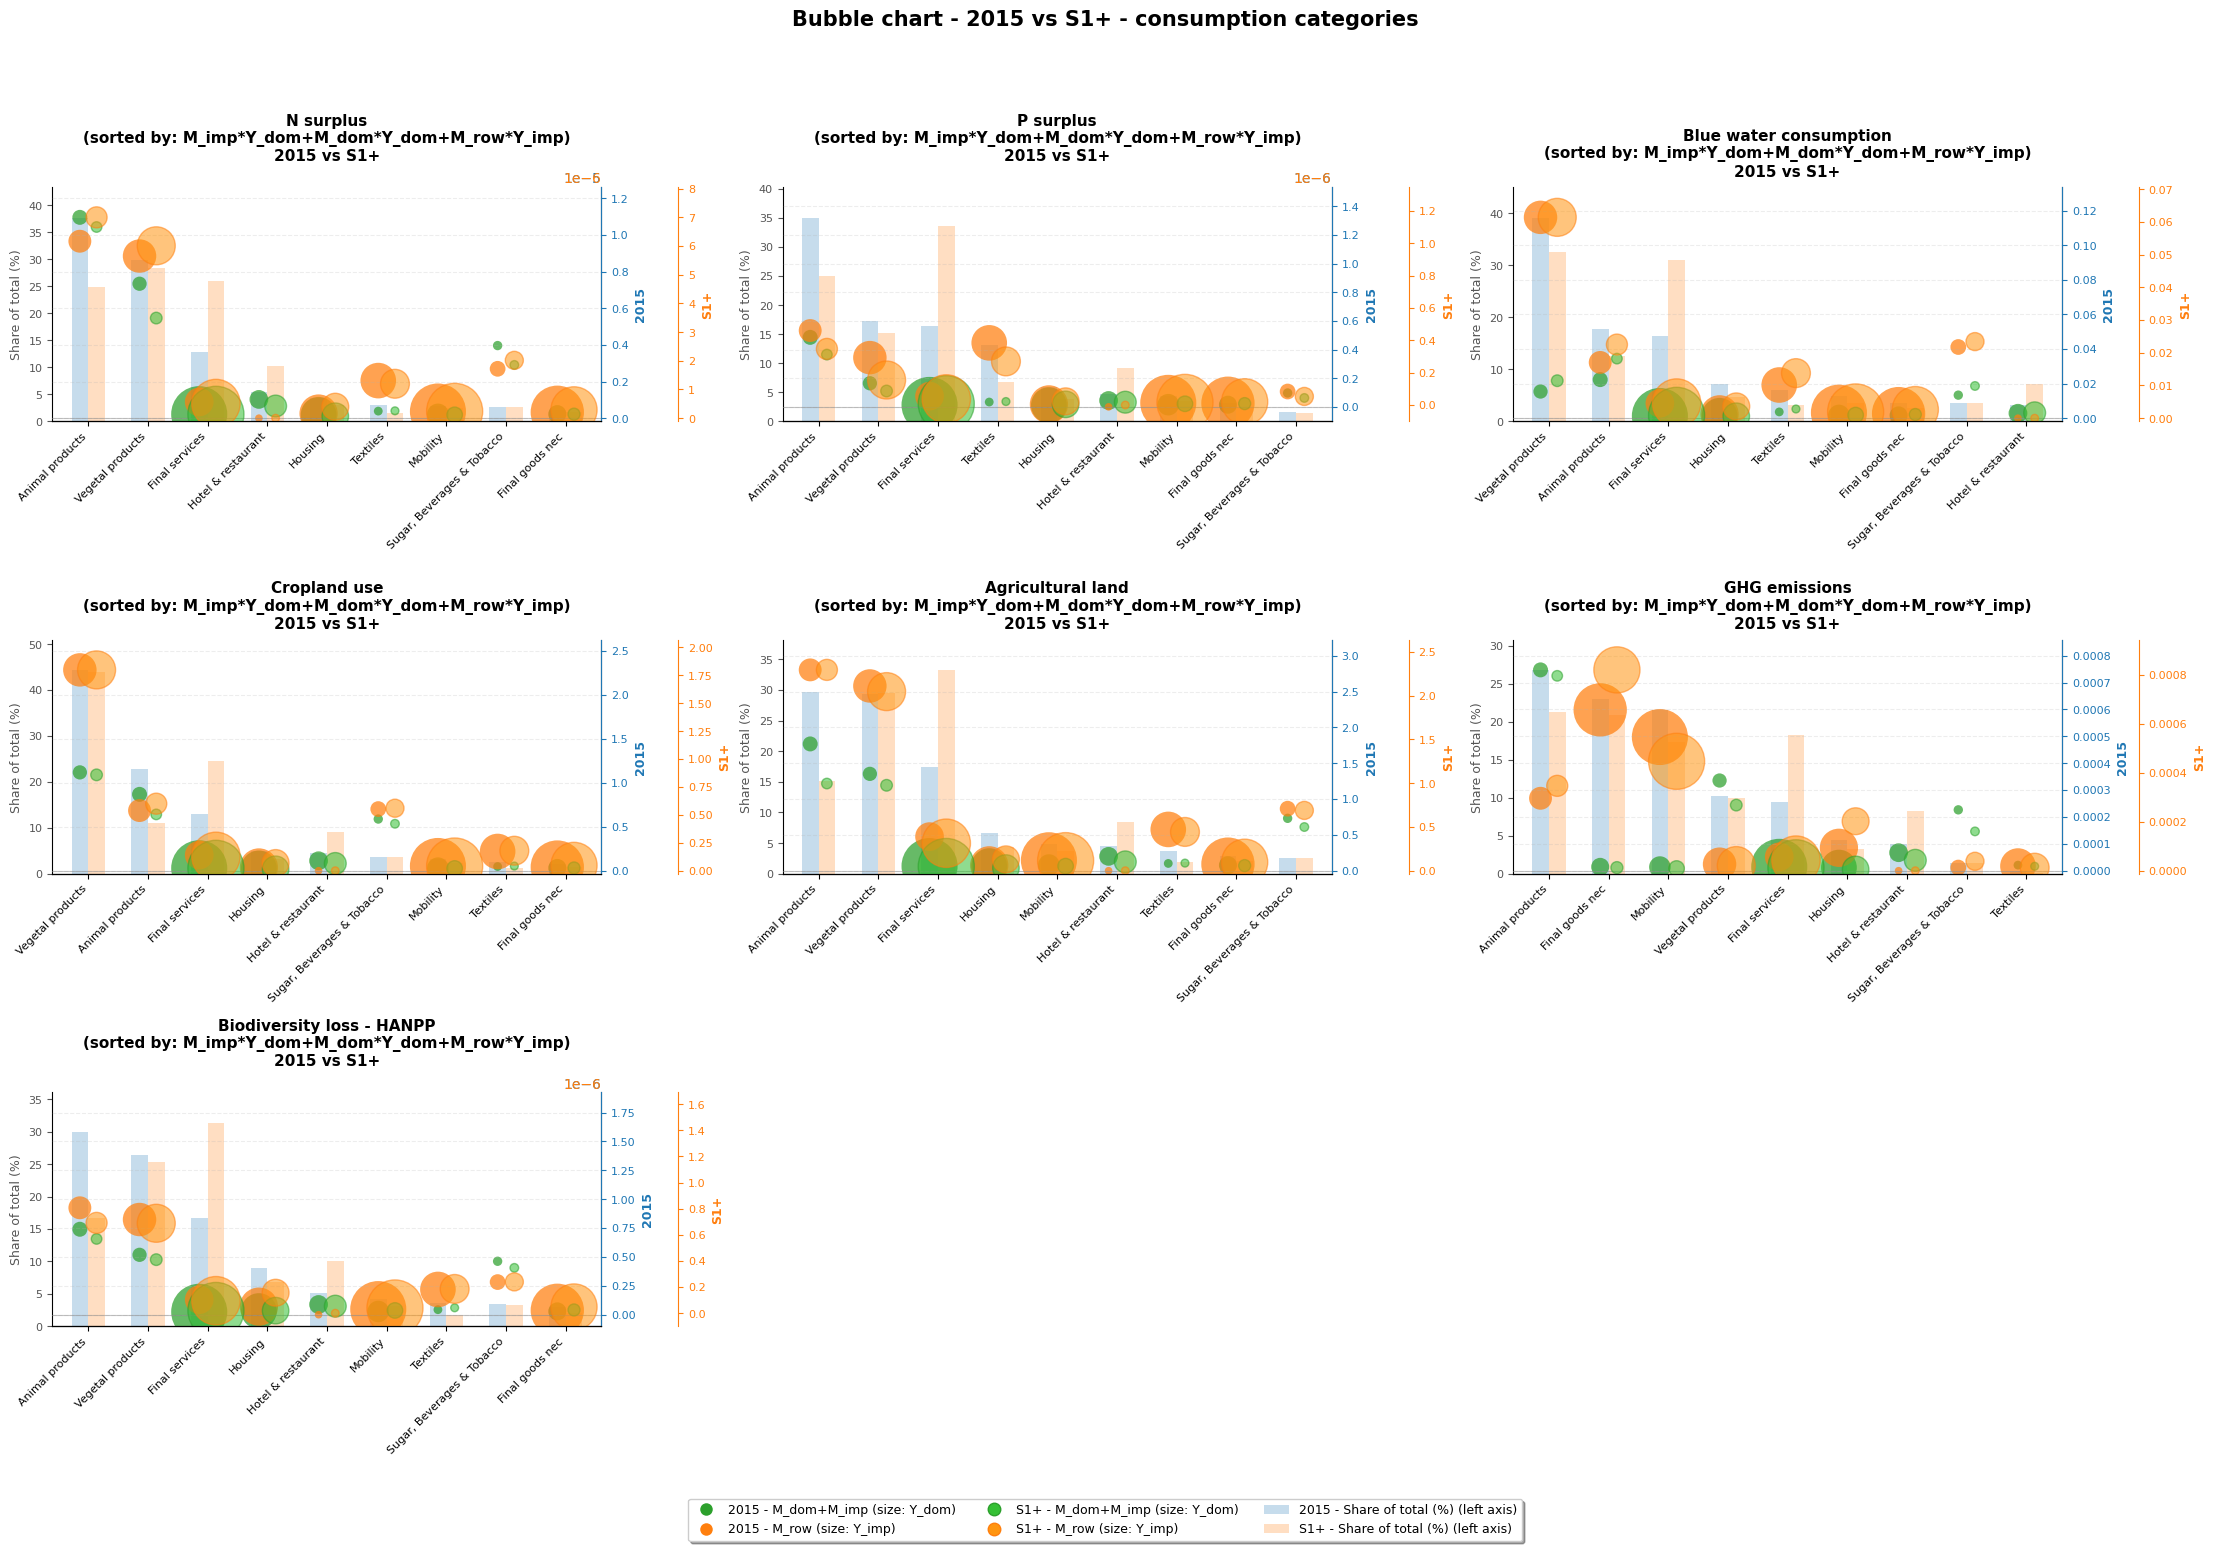

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\driver_comparison\_agri\bubble_chart_2015_vs_S1+_categories.png


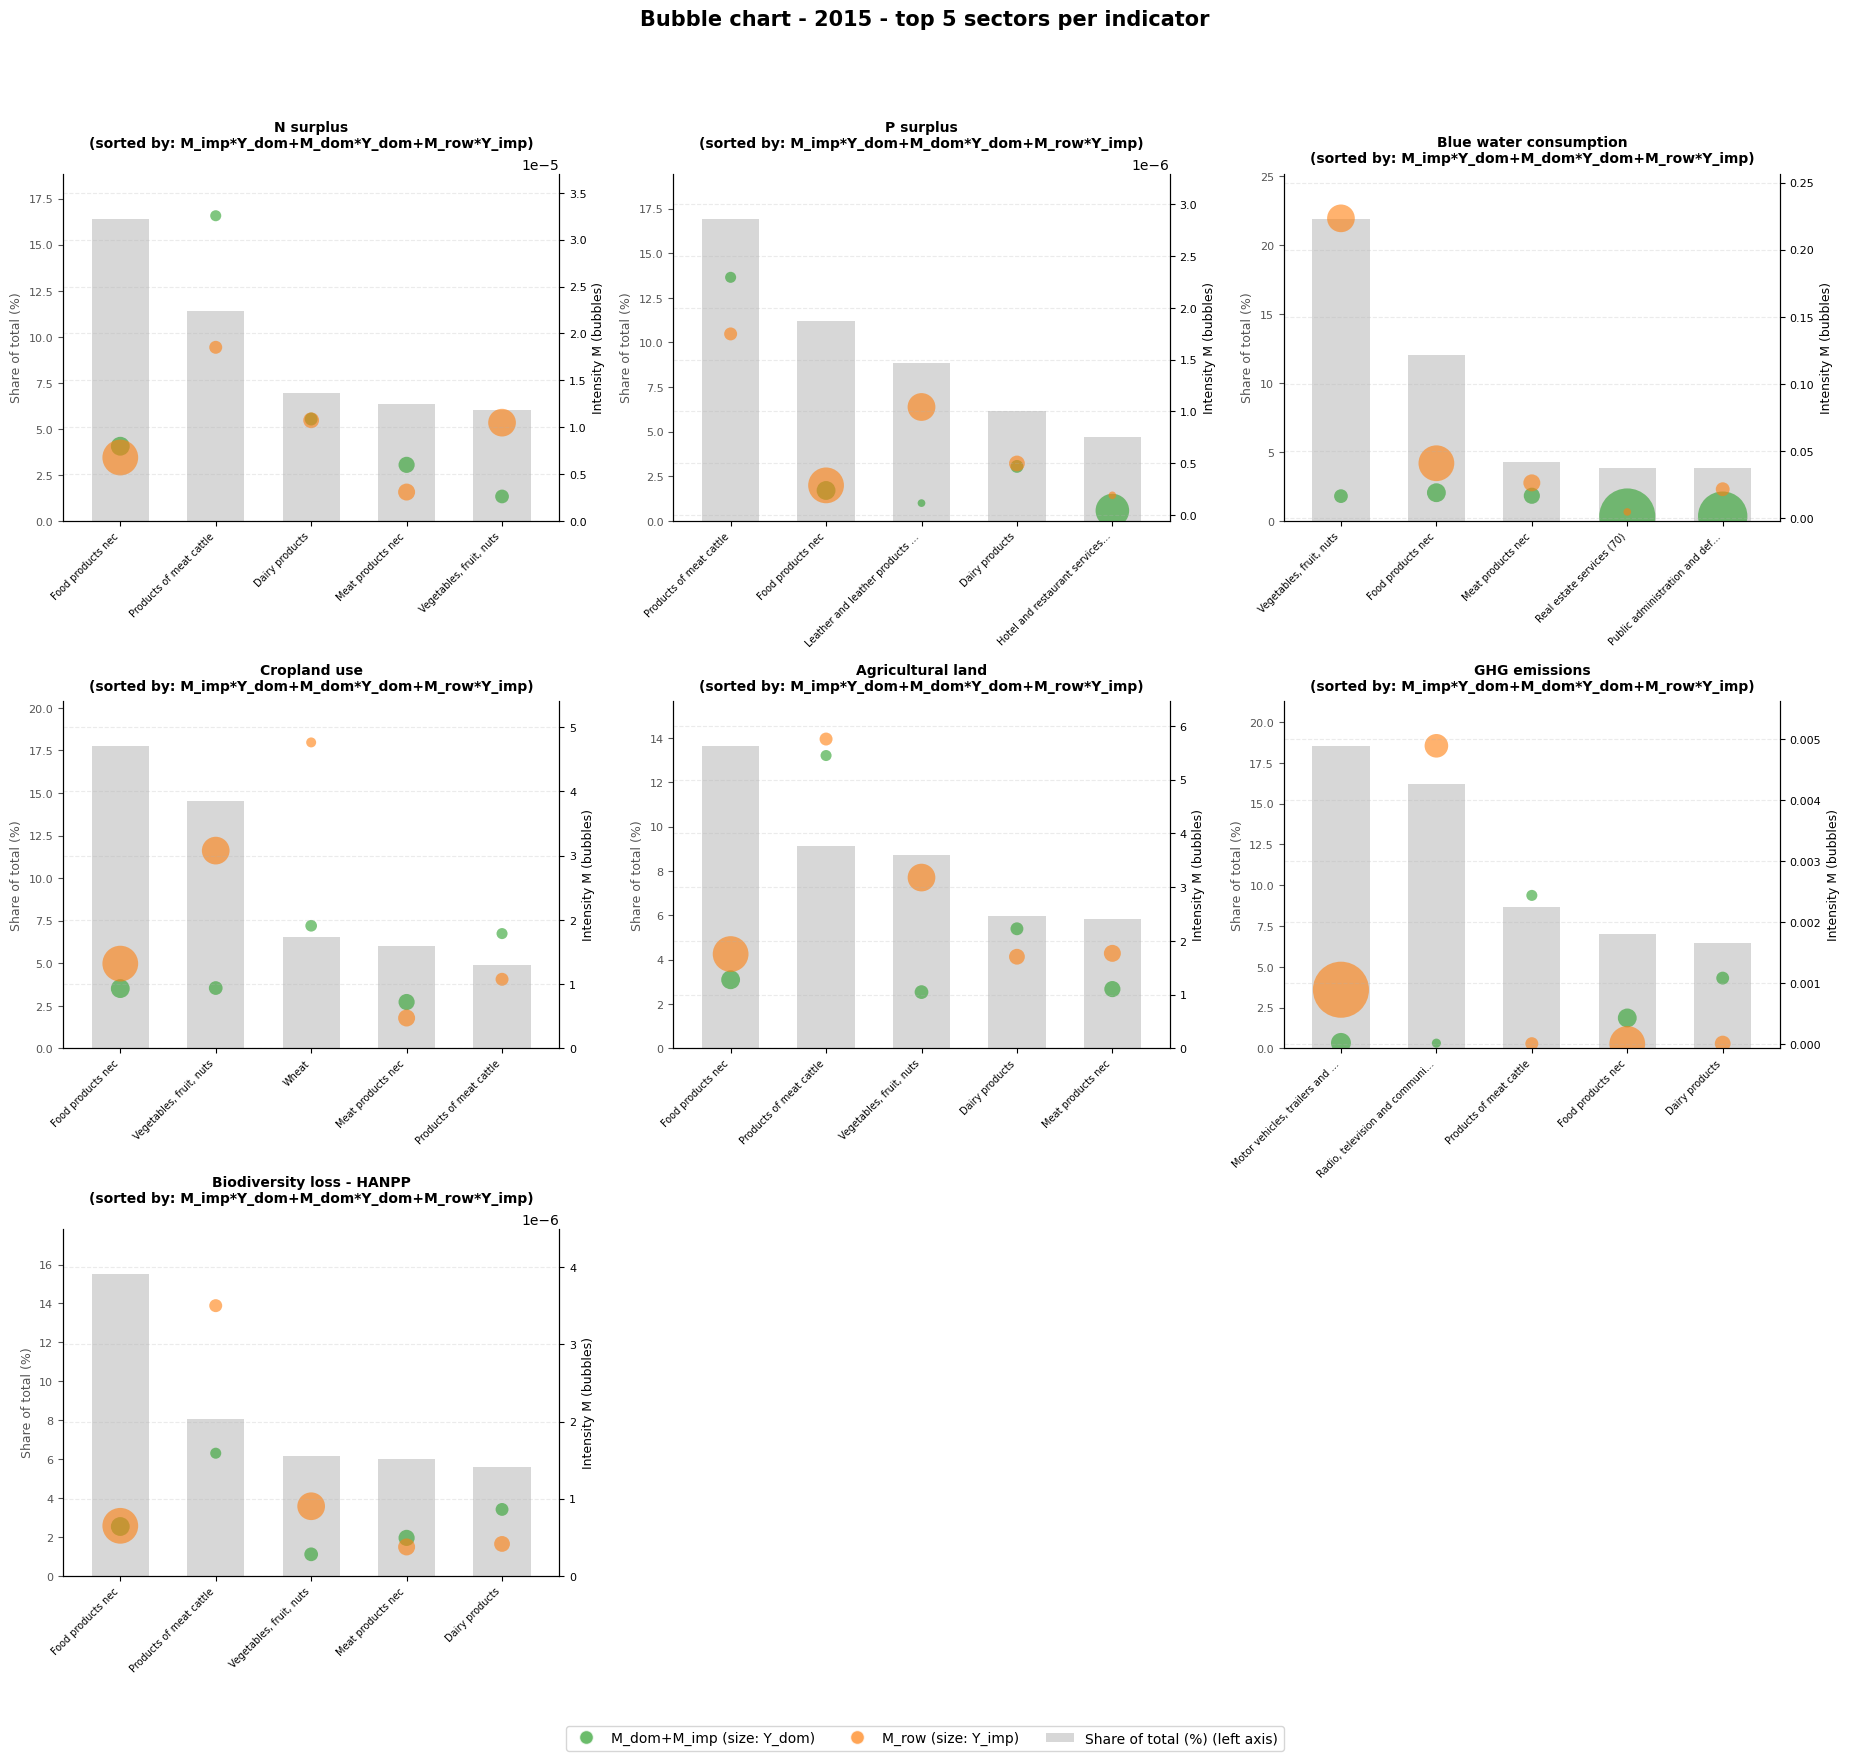

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\driver_comparison\_agri\bubble_chart_2015_top5_products.png


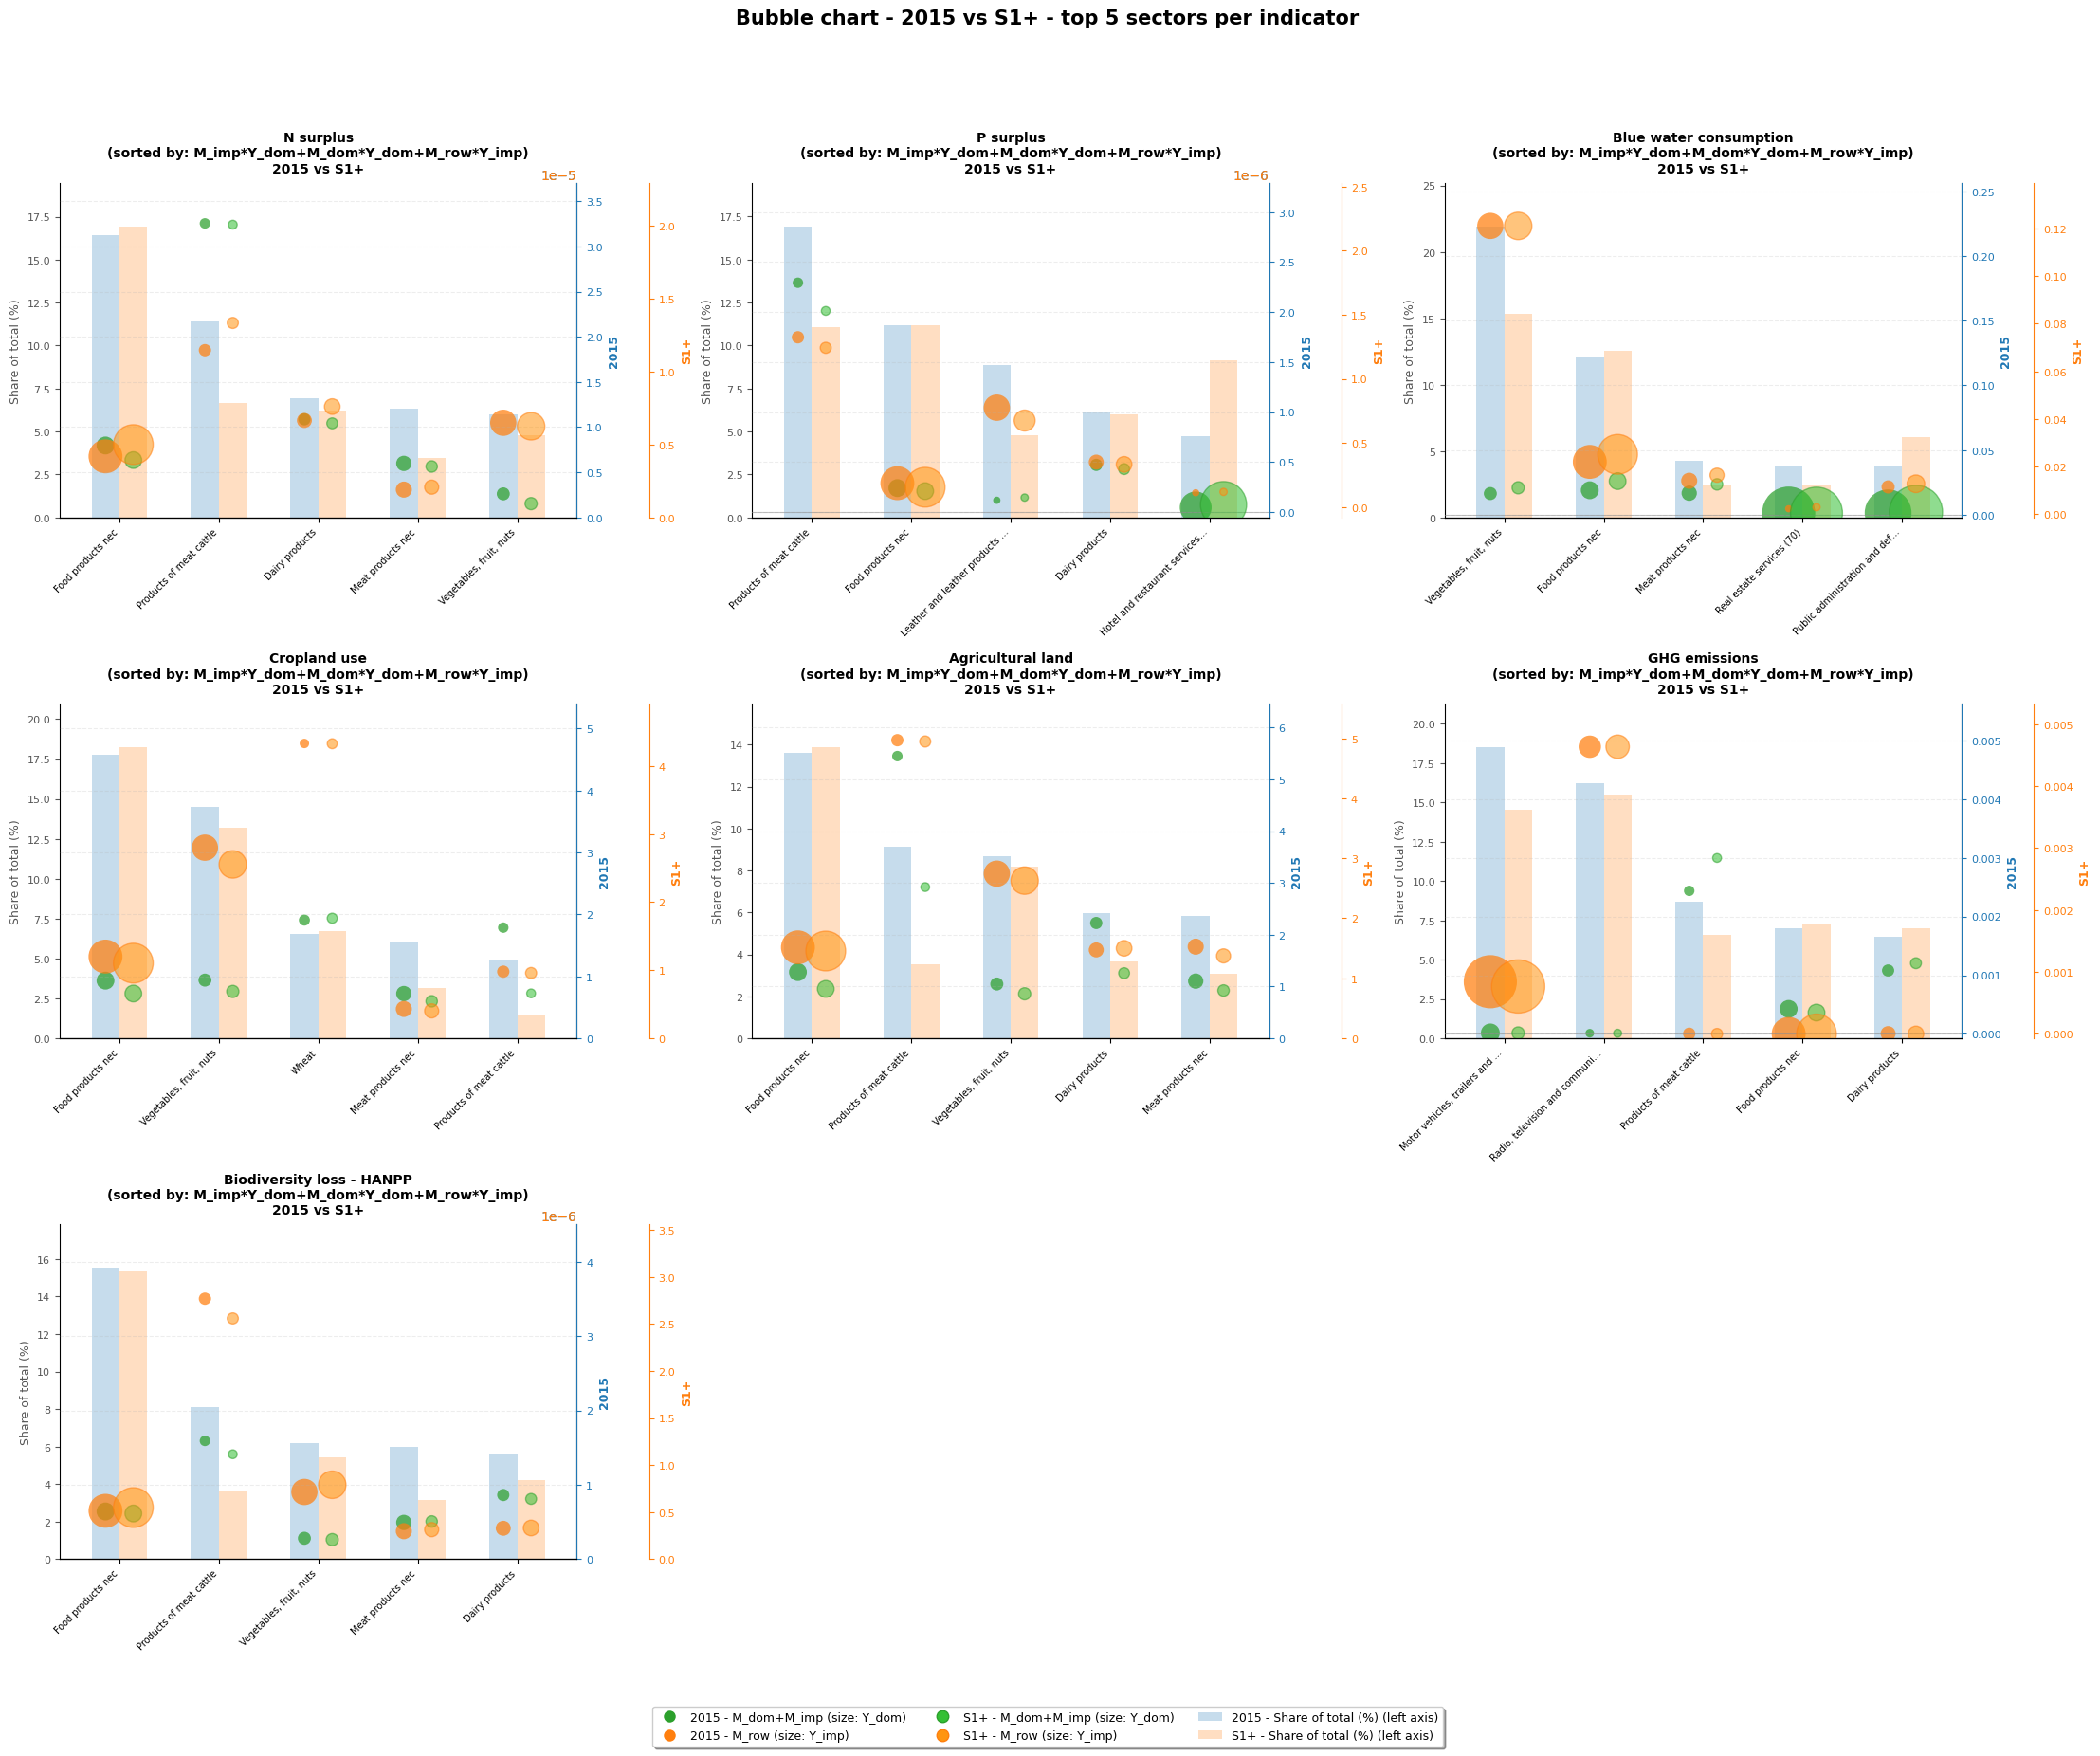

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\driver_comparison\_agri\bubble_chart_2015_vs_S1+_top5_products.png


In [13]:
BRIDGE_SHEET = "M_split"          # sector grouping of bridge_matrices.xlsx: "M" (5 categories) or "M_split" (12)
COMPARISON_SCENARIO = "S1+"       # transition scenario compared with the reference (a GROUP_France folder)
BUBBLE_TYPES = ["categories", "products"]  # "categories": consumption categories; "products": first N_PRODUCTS sectors
N_PRODUCTS = 5                    # number of sectors for "products"
BUBBLE_COMPARE = [False, True]    # False: reference alone; True: reference vs COMPARISON_SCENARIO
OVERWRITE_EXCEL = True            # True: regenerate bubble_data_*.xlsx; False: keep existing ones (sort row B1 edited by hand)

folders, _, _, _ = scenarios(GROUP_France)
cf_df, _ = inputs(GROUP_France)
bridge_m = io.load_bridge_m_matrix(BRIDGE_SHEET)
out_dir = config.figure_dir("driver_comparison", *AGRI_DIR)
ref = folders[config.REFERENCE_SCENARIO_IDX]
comp = next(f for f in folders if f.name == COMPARISON_SCENARIO)


def excel_is_up_to_date(path):
    """True if the workbook has the categories of the current bridge and the current format."""
    sheets = load_indicator_tables_excel(path)
    expected = [str(c) for c in bridge_m.columns]
    return bool(sheets) and all(s["categories"] == expected and s["categories_sorted"] for s in sheets.values())


excel = {}
for f in (ref, comp):
    excel[f.name] = out_dir / f"bubble_data_by_indicator_{f.name}.xlsx"
    if OVERWRITE_EXCEL or not excel[f.name].exists() or not excel_is_up_to_date(excel[f.name]):
        export_indicator_tables_excel(f, cf_df, bridge_m, excel[f.name])
        print(f"Excel table saved: {excel[f.name]}")

for type_ in BUBBLE_TYPES:
    for compare in BUBBLE_COMPARE:
        suffix = type_ if type_ == "categories" else f"top{N_PRODUCTS}_products"
        scope = f"{ref.name}_vs_{comp.name}" if compare else ref.name
        path = out_dir / f"bubble_chart_{scope}_{suffix}.png"
        fig, _ = create_driver_comparison(excel[ref.name], type=type_, n=N_PRODUCTS, scenarios=compare,
                                          comparison_excel_path=excel[comp.name],
                                          excel_path=path.with_suffix(".xlsx"))
        save(fig, path)

## 6. Pressure shares in biodiversity impacts

c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\config.py:232: UserWarning: Group 'CONF_agri' does not contain Base_year_2015: the reference scenario (REFERENCE_SCENARIO_IDX) will be the first one in alphabetical order.
  warnings.warn(
c:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\notebooks\planefr_lib\plot_process_breakdown.py:127: RuntimeWarning: invalid value encountered in divide
  heights_pct = np.where(totals > 0, heights / totals * 100, 0)


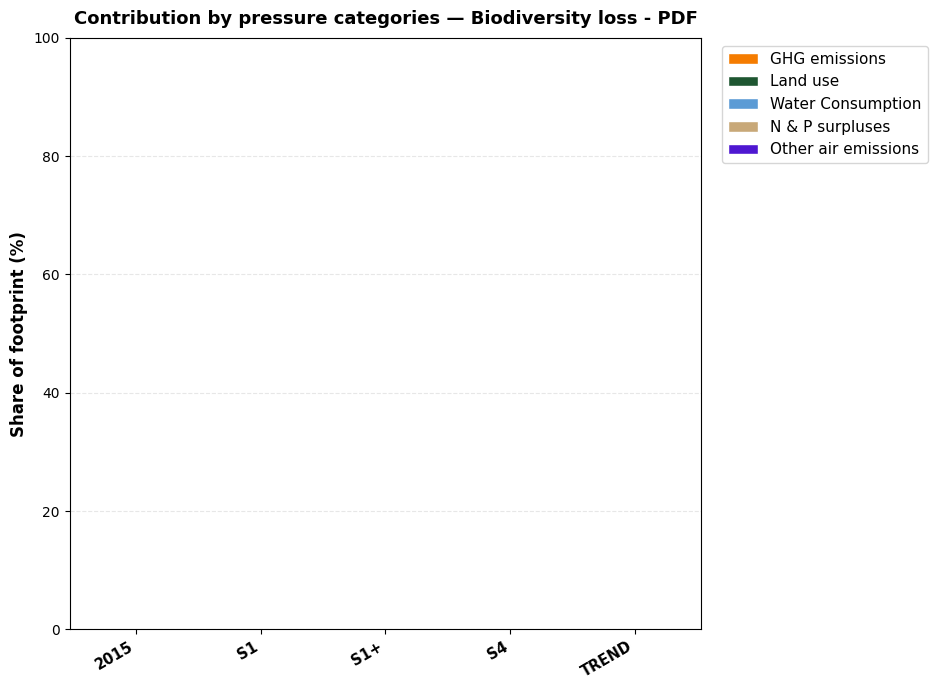

Saved: C:\Users\Arnaud\Documents\CIRED\PlaneFR\Code\Module_PlaneFR\figures\biodiversity_process_contribution\_agri\biodiversity_loss_process_contribution.png


In [14]:
INDICATOR_NAME = "Biodiversity loss - PDF"  # indicator of indicator_computing.xlsx whose footprint is broken down by pressure

cf_df, boundaries_df = inputs(GROUP_France)
folders = config.get_scenario_folders(exclude_2019=True, scenario_group=GROUP_France)
lp_values = [processing.process_indicator_lp_breakdown(INDICATOR_NAME, f, cf_df, boundaries_df)
             for f in folders]

path = config.figure_dir("biodiversity_process_contribution", *AGRI_DIR) / "biodiversity_loss_process_contribution.png"
fig, _ = create_biodiversity_process_contribution(
    lp_values, [f.name for f in folders], indicator_name=INDICATOR_NAME,
    unit=figure_export.indicator_unit(boundaries_df, INDICATOR_NAME),
    excel_path=path.with_suffix(".xlsx"))
save(fig, path)